# Does it affect Shares?

NOTE: shares > log(1+shares)

In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/mini_project_1_data.csv")

import numpy as np

df["shares"] = np.log1p(df["shares"])

## time delta

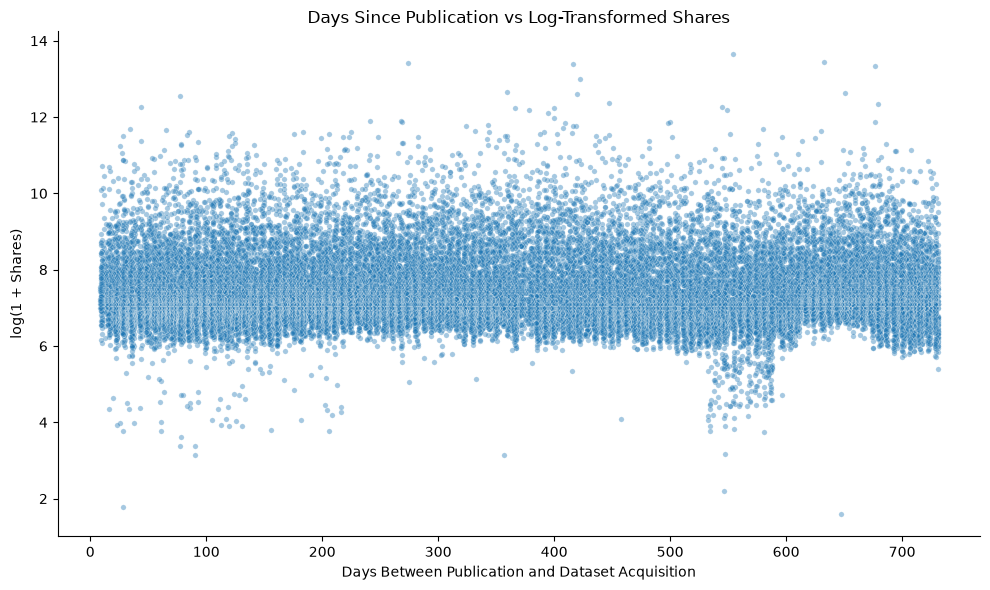

In [18]:
import numpy as np

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="timedelta",
    y=df["shares"],
    alpha=0.4,
    s=15
)

plt.title("Days Since Publication vs Log-Transformed Shares")
plt.xlabel("Days Between Publication and Dataset Acquisition")
plt.ylabel("log(1 + Shares)")

sns.despine()
plt.tight_layout()
plt.show()

## weekday

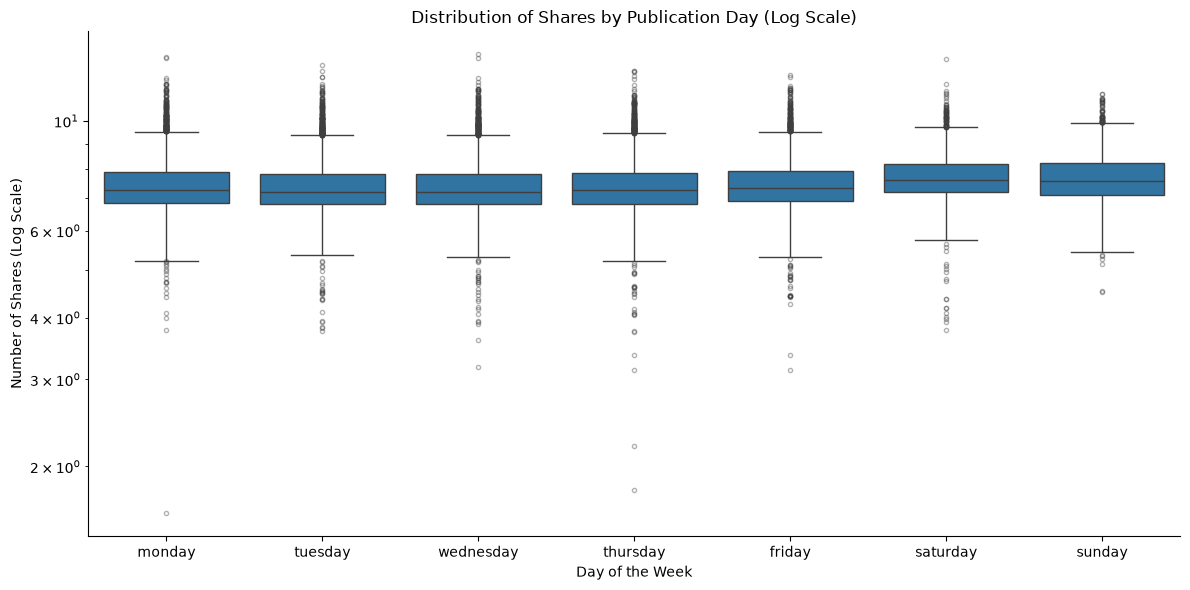

In [ ]:
import matplotlib as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="weekday",
    y="shares",
    order=weekday_order,
    showfliers=True,
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.4}
)

plt.yscale("log")
plt.title("Distribution of Shares by Publication Day (Log Scale)")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Shares (Log Scale)")

sns.despine()
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

weekday_order = [
    "monday", "tuesday", "wednesday",
    "thursday", "friday", "saturday", "sunday"
]

df_test = df[["weekday", "shares"]].dropna().copy()

results = []

for day in weekday_order:
    group = df_test.loc[
        df_test["weekday"] == day, "shares"
    ]

    other = df_test.loc[
        df_test["weekday"] != day, "shares"
    ]

    t_stat, p_value = ttest_ind(
        group,
        other,
        equal_var=False
    )

    results.append({
        "weekday": day,
        "n": len(group),
        "mean_shares": group.mean(),
        "other_days_mean": other.mean(),
        "mean_difference": group.mean() - other.mean(),
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

display(results_df.round(5))

,weekday,n,mean_shares,other_days_mean,mean_difference,p_value,p_adjusted,significant
0,monday,5977,7.45658,7.47938,-0.02280,0.09217,0.18435,False
1,tuesday,6646,7.41742,7.48887,-0.07145,0.00000,0.00000,True
2,wednesday,6663,7.39933,7.49306,-0.09373,0.00000,0.00000,True
3,thursday,6563,7.41931,7.48824,-0.06892,0.00000,0.00000,True
4,friday,5147,7.48987,7.47315,0.01672,0.22431,0.22431,False
5,saturday,2212,7.76785,7.45624,0.31161,0.00000,0.00000,True
6,sunday,2472,7.74120,7.45578,0.28541,0.00000,0.00000,True


## number of words

we also probably will convert n_tokens_content to log scale

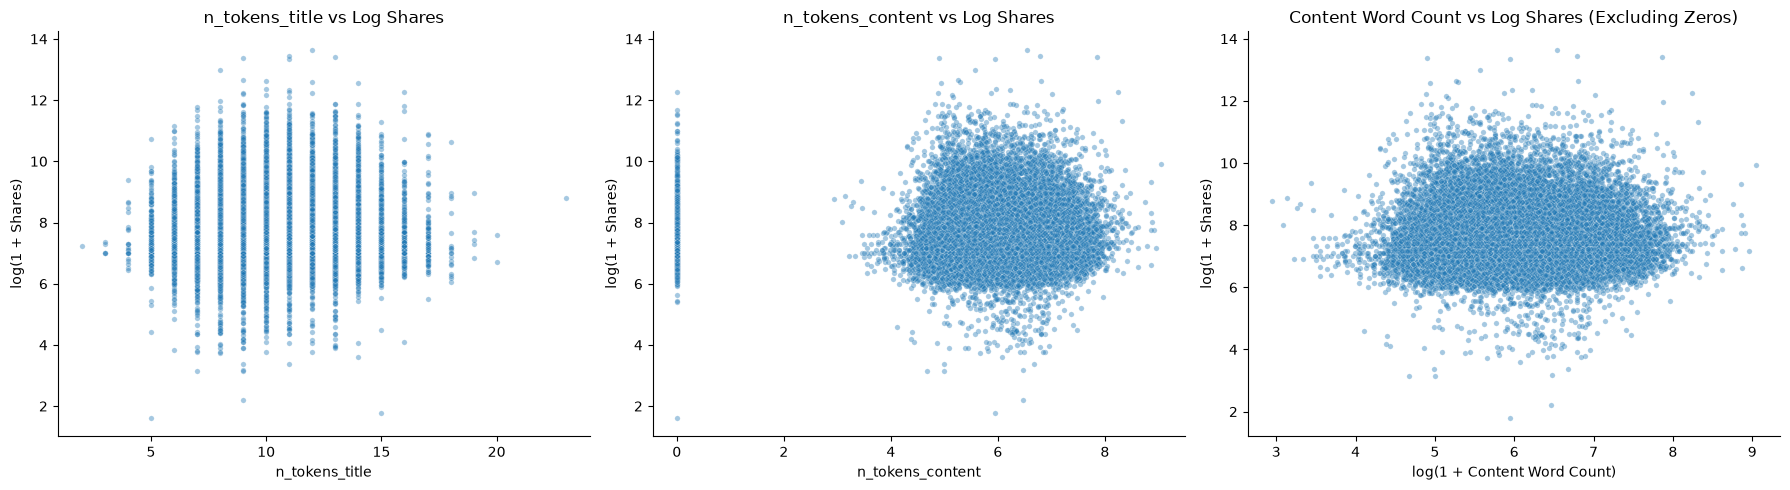

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["n_tokens_title", "n_tokens_content"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes[:2], features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="shares",
        alpha=0.4,
        s=15,
        ax=ax
    )

    ax.set_title(f"{feature} vs Log Shares")
    ax.set_xlabel(feature)
    ax.set_ylabel("log(1 + Shares)")

# Content word count excluding zeros
df_nonzero = df[df["n_tokens_content"] > 0]

sns.scatterplot(
    data=df_nonzero,
    x="n_tokens_content",
    y="shares",
    alpha=0.4,
    s=15,
    ax=axes[2]
)

axes[2].set_title("Content Word Count vs Log Shares (Excluding Zeros)")
axes[2].set_xlabel("log(1 + Content Word Count)")
axes[2].set_ylabel("log(1 + Shares)")

sns.despine()
plt.tight_layout()
plt.show()

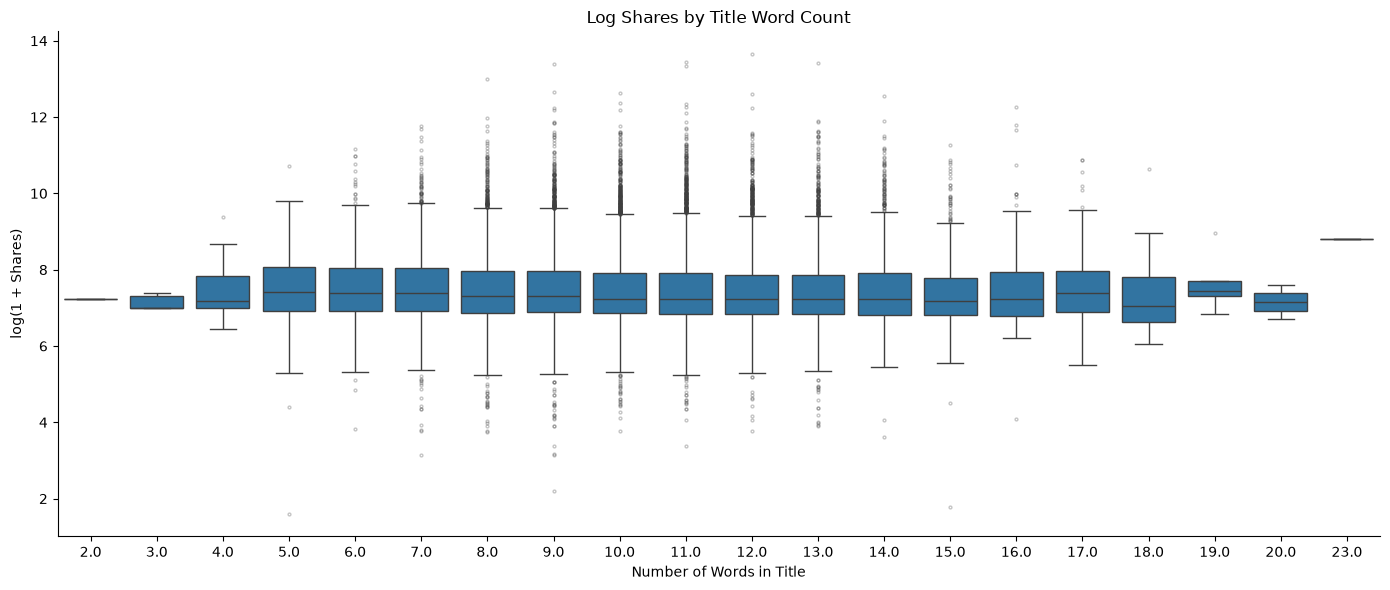

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="n_tokens_title",
    y="shares",
    showfliers=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.3}
)

plt.title("Log Shares by Title Word Count")
plt.xlabel("Number of Words in Title")
plt.ylabel("log(1 + Shares)")

sns.despine()
plt.tight_layout()
plt.show()

In [37]:
display(
    df["n_tokens_title"]
    .value_counts()
    .sort_index()
    .to_frame()
    .T
    .rename(index={"count": "n_articles"})
)

n_tokens_title,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,23.0
n_articles,1,5,23,168,726,1891,3844,5662,6627,6258,4742,3140,1563,690,229,83,20,5,2,1


In [38]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    df["n_tokens_title"],
    df["shares"],
    nan_policy="omit"
)

print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p_value:.4g}")
print(f"Statistically significant: {p_value < 0.05}")

Spearman rho: -0.0406
P-value: 1.613e-14
Statistically significant: True


Spearman's rank correlation identified a statistically significant but negligible negative association between title word count and article shares (ρ = −0.0406, p = 1.61 × 10⁻¹⁴). Although the result suggests that longer titles are associated with marginally fewer shares, the extremely small effect size indicates little practical monotonic relationship. Further investigation of potential nonlinear effects and out-of-sample predictive performance is warranted before determining the feature's usefulness.

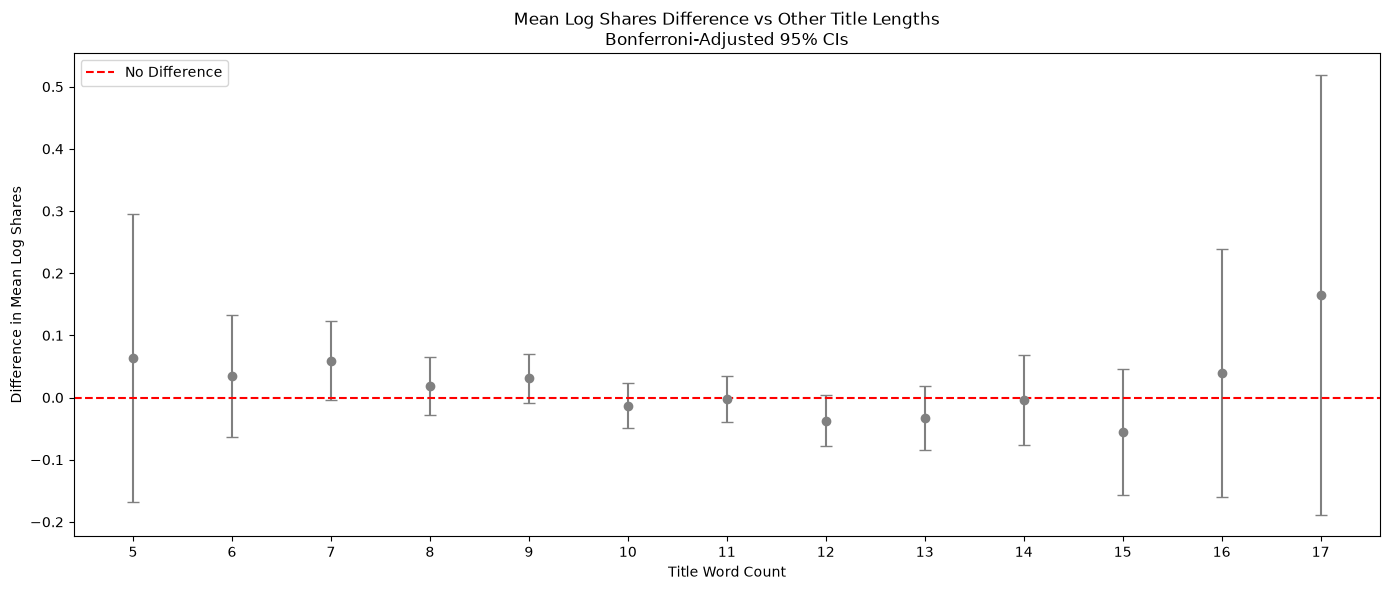

,title_word_count,n,mean_difference,se,df_welch,p_value,p_adjusted,significant,ci_lower,ci_upper
0,5.0,168,0.06322,0.07912,168.30192,0.42538,1.00000,False,-0.16869,0.29513
1,6.0,726,0.03461,0.03378,757.42900,0.30586,1.00000,False,-0.06333,0.13256
2,7.0,1891,0.05908,0.02205,2104.61516,0.00743,0.09665,False,-0.00473,0.12290
3,8.0,3844,0.01897,0.01601,4794.22033,0.23603,1.00000,False,-0.02732,0.06526
4,9.0,5662,0.03096,0.01354,7902.10998,0.02218,0.24401,False,-0.00817,0.07010
5,10.0,6627,-0.01291,0.01238,10117.21095,0.29705,1.00000,False,-0.04869,0.02287
6,11.0,6258,-0.00204,0.01295,9095.86391,0.87499,1.00000,False,-0.03949,0.03541
7,12.0,4742,-0.03719,0.01421,6370.38290,0.00886,0.10638,False,-0.07827,0.00389
8,13.0,3140,-0.03348,0.01772,3738.41785,0.05885,0.58849,False,-0.08472,0.01776
9,14.0,1563,-0.00462,0.02500,1695.76093,0.85324,1.00000,False,-0.07698,0.06773


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from statsmodels.stats.multitest import multipletests

df_test = df[["n_tokens_title", "shares"]].dropna().copy()

min_samples = 30
results = []

for word_count in sorted(df_test["n_tokens_title"].unique()):

    group = df_test.loc[
        df_test["n_tokens_title"] == word_count, "shares"
    ]

    other = df_test.loc[
        df_test["n_tokens_title"] != word_count, "shares"
    ]

    if len(group) < min_samples or len(other) < min_samples:
        continue

    n1, n2 = len(group), len(other)
    var1, var2 = group.var(ddof=1), other.var(ddof=1)

    mean_diff = group.mean() - other.mean()

    # Welch standard error
    se = np.sqrt(var1 / n1 + var2 / n2)

    # Welch-Satterthwaite degrees of freedom
    df_welch = (var1/n1 + var2/n2)**2 / (
        (var1/n1)**2 / (n1-1) +
        (var2/n2)**2 / (n2-1)
    )

    t_stat = mean_diff / se
    p_value = 2 * t.sf(abs(t_stat), df_welch)

    results.append({
        "title_word_count": word_count,
        "n": n1,
        "mean_difference": mean_diff,
        "se": se,
        "df_welch": df_welch,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# Holm-adjusted p-values
results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

# Bonferroni-adjusted simultaneous 95% CIs
# (Conservative, but compatible with family-wise inference)
m = len(results_df)
critical = t.ppf(
    1 - 0.05 / (2 * m),
    results_df["df_welch"]
)

results_df["ci_lower"] = (
    results_df["mean_difference"] - critical * results_df["se"]
)

results_df["ci_upper"] = (
    results_df["mean_difference"] + critical * results_df["se"]
)

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

for _, row in results_df.iterrows():
    color = "tab:blue" if row["significant"] else "gray"

    ax.errorbar(
        row["title_word_count"],
        row["mean_difference"],
        yerr=[
            [row["mean_difference"] - row["ci_lower"]],
            [row["ci_upper"] - row["mean_difference"]]
        ],
        fmt="o",
        color=color,
        capsize=4
    )

ax.axhline(0, color="red", linestyle="--", label="No Difference")

ax.set_title(
    "Mean Log Shares Difference vs Other Title Lengths\n"
    "Bonferroni-Adjusted 95% CIs"
)
ax.set_xlabel("Title Word Count")
ax.set_ylabel("Difference in Mean Log Shares")
ax.set_xticks(results_df["title_word_count"])
ax.legend()

plt.tight_layout()
plt.show()

display(results_df.round(5))

Further analysis using Welch's t-tests compared the mean log-shares of each sufficiently represented title length against all other lengths, with Holm correction for multiple comparisons. None of the 13 tested title lengths demonstrated a statistically significant difference at the 5% significance level. These findings suggest that title length alone has limited explanatory value for article popularity, although potential nonlinear relationships and interactions with other features remain unexplored.

## num_hrefs & num_self_hrefs

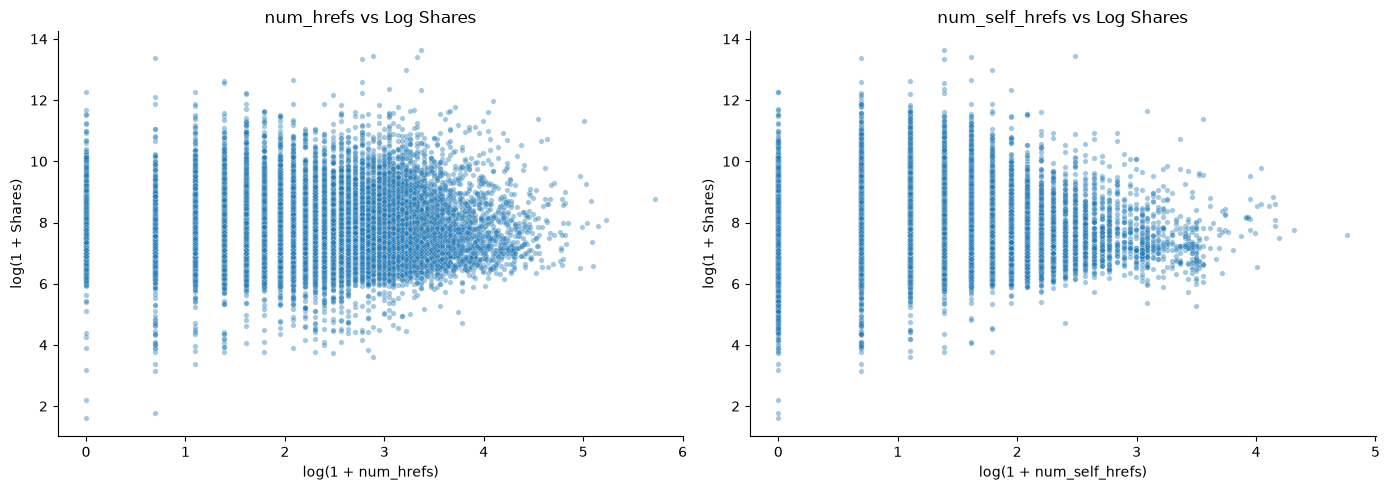

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

features = ["num_hrefs", "num_self_hrefs"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, features):
    sns.scatterplot(
        x=np.log1p(df[feature]),
        y=df["shares"],
        alpha=0.4,
        s=15,
        ax=ax
    )

    ax.set_title(f"{feature} vs Log Shares")
    ax.set_xlabel(f"log(1 + {feature})")
    ax.set_ylabel("log(1 + Shares)")

sns.despine()
plt.tight_layout()
plt.show()

In [54]:
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

results = []

for feature in features:
    rho, p_value = spearmanr(
        df[feature],
        df["shares"],
        nan_policy="omit"
    )

    results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

display(results_df.round(5))

,feature,spearman_rho,p_value,p_adjusted,significant
0,num_hrefs,0.08963,0.0,0.0,True
1,num_self_hrefs,0.03634,0.0,0.0,True


Both the total number of hyperlinks (num_hrefs) and internal hyperlinks (num_self_hrefs) exhibit statistically significant but very weak positive monotonic associations with article shares. Spearman's rank correlations were 0.0896 and 0.0363, respectively, with Holm-adjusted p-values below 0.05. Although articles containing more hyperlinks tend to receive marginally more shares, the small correlation coefficients suggest limited standalone predictive information.

## data channel

In [56]:
display(df["data_channel"].value_counts(dropna=False))

data_channel
world            7573
technology       6642
entertainment    6407
business         5623
NaN              5462
social_media     2089
lifestyle        1884
Name: count, dtype: int64

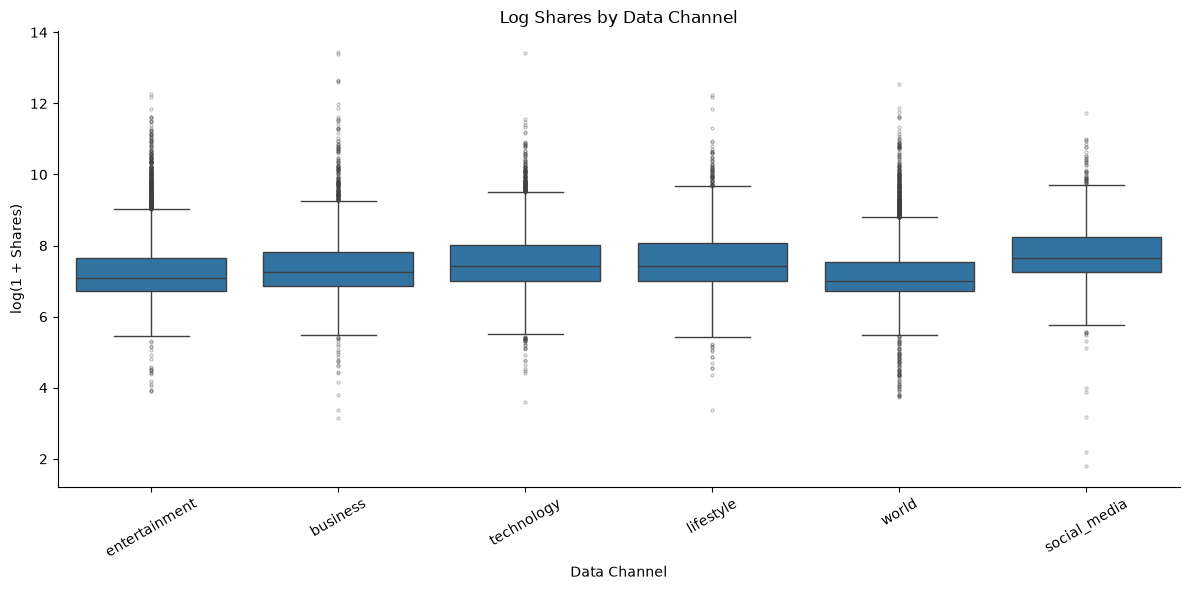

In [57]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="data_channel",
    y="shares",
    showfliers=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.3}
)

plt.title("Log Shares by Data Channel")
plt.xlabel("Data Channel")
plt.ylabel("log(1 + Shares)")
plt.xticks(rotation=30)

sns.despine()
plt.tight_layout()
plt.show()

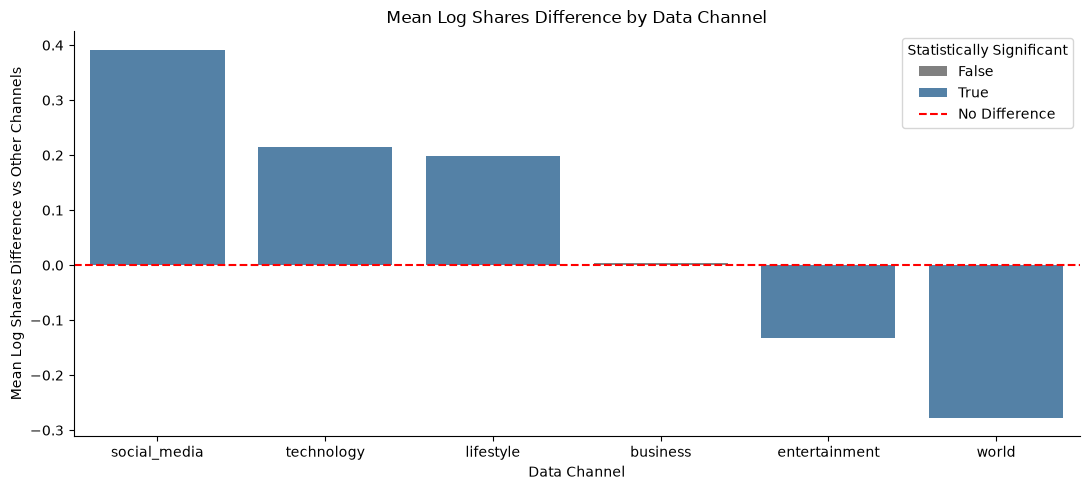

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = results_df.sort_values("mean_difference", ascending=False)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_df,
    x="data_channel",
    y="mean_difference",
    hue="significant",
    palette={True: "steelblue", False: "gray"},
    dodge=False
)

plt.axhline(0, color="red", linestyle="--", label="No Difference")

plt.title("Mean Log Shares Difference by Data Channel")
plt.xlabel("Data Channel")
plt.ylabel("Mean Log Shares Difference vs Other Channels")
plt.legend(title="Statistically Significant")

sns.despine()
plt.tight_layout()
plt.show()

In [58]:
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

df_test = df[["data_channel", "shares"]].dropna().copy()

results = []

for channel in sorted(df_test["data_channel"].unique()):

    group = df_test.loc[
        df_test["data_channel"] == channel, "shares"
    ]

    other = df_test.loc[
        df_test["data_channel"] != channel, "shares"
    ]

    if len(group) < 30 or len(other) < 30:
        continue

    t_stat, p_value = ttest_ind(
        group, other, equal_var=False
    )

    results.append({
        "data_channel": channel,
        "n": len(group),
        "mean_difference": group.mean() - other.mean(),
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

display(results_df.sort_values("p_adjusted"))

,data_channel,n,mean_difference,p_value,p_adjusted,significant
5,world,7573,-0.277222,2.852966e-132,1.711780e-131,True
3,social_media,2089,0.391698,2.977140e-87,1.488570e-86,True
4,technology,6642,0.214072,2.086054e-76,8.344214e-76,True
1,entertainment,6407,-0.132493,7.770450e-25,2.331135e-24,True
2,lifestyle,1884,0.198563,1.420511e-18,2.841022e-18,True
0,business,5623,0.004450,7.218601e-01,7.218601e-01,False


## self_reference_XXX_shares

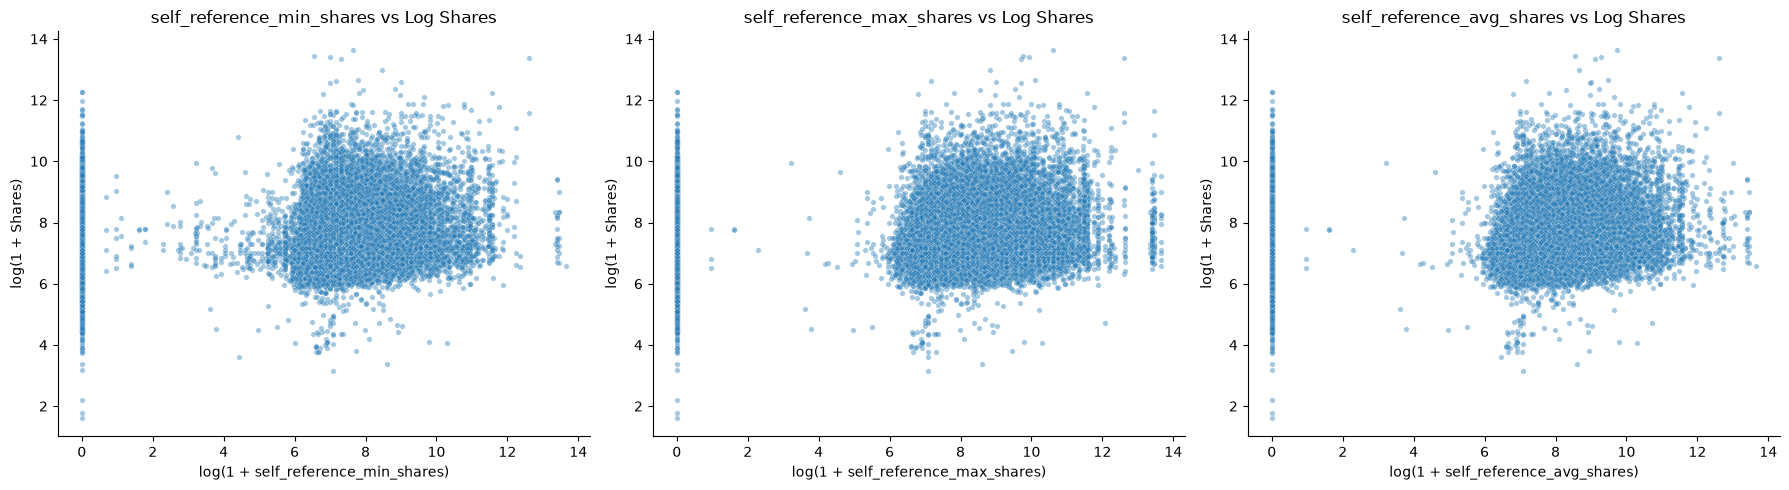

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "self_reference_min_shares",
    "self_reference_max_shares",
    "self_reference_avg_shares"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, features):
    sns.scatterplot(
        x=np.log1p(df[feature]),
        y=df["shares"],
        alpha=0.4,
        s=15,
        ax=ax
    )

    ax.set_title(f"{feature} vs Log Shares")
    ax.set_xlabel(f"log(1 + {feature})")
    ax.set_ylabel("log(1 + Shares)")

sns.despine()
plt.tight_layout()
plt.show()

In [63]:
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

results = []

for feature in features:
    rho, p_value = spearmanr(
        df[feature],
        df["shares"],
        nan_policy="omit"
    )

    results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

results_display = results_df.copy()

results_display["spearman_rho"] = results_display["spearman_rho"].round(5)

results_display["p_value"] = results_display["p_value"].map("{:.3e}".format)

results_display["p_adjusted"] = results_display["p_adjusted"].map("{:.3e}".format)

display(results_display)

,feature,spearman_rho,p_value,p_adjusted,significant
0,self_reference_min_shares,0.17992,3.863e-252,7.726e-252,True
1,self_reference_max_shares,0.16777,4.754e-219,4.754e-219,True
2,self_reference_avg_shares,0.19094,2.623e-284,7.869e-284,True


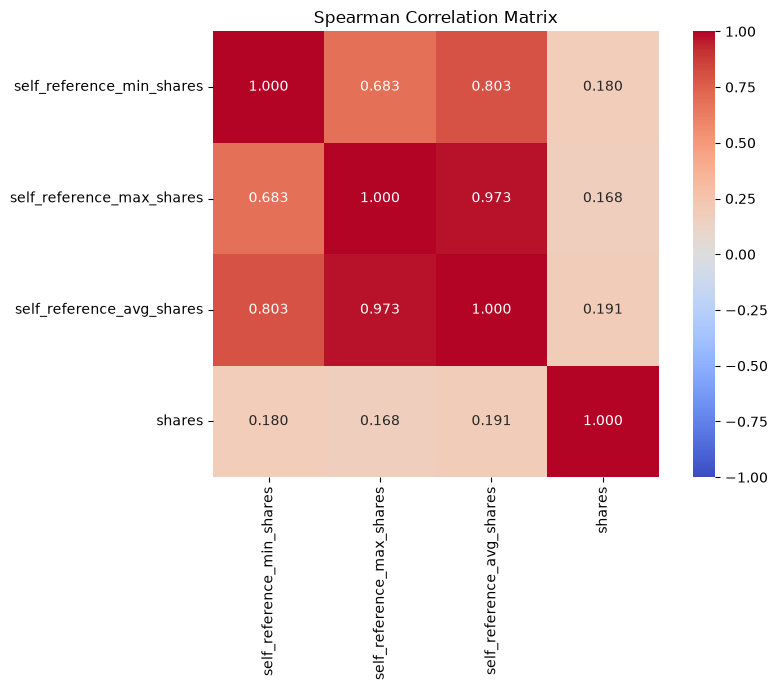

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "self_reference_min_shares",
    "self_reference_max_shares",
    "self_reference_avg_shares",
    "shares"
]

corr_matrix = df[features].corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

Remove highly correlated features?

Not automatically. It depends on your model.
- Linear regression: Strong predictor correlations can create multicollinearity, making individual coefficients unstable and difficult to interpret.
- Random forests and gradient-boosted trees: These models can often handle correlated predictors, although feature importance may become harder to interpret.
- Feature selection: You can compare models using all three features versus reduced subsets through cross-validation.

## keywords

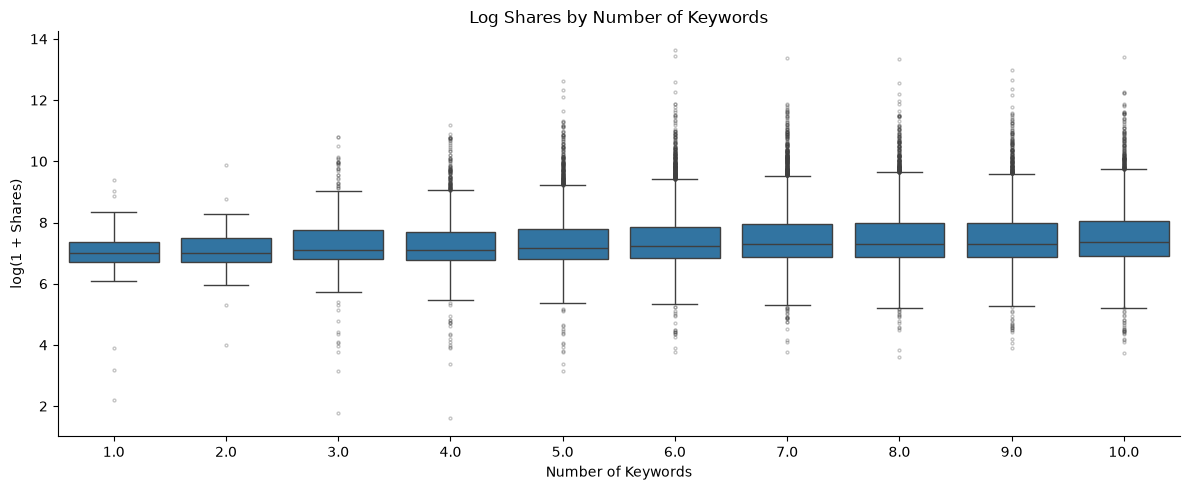

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="num_keywords",
    y="shares",
    showfliers=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.3}
)

plt.title("Log Shares by Number of Keywords")
plt.xlabel("Number of Keywords")
plt.ylabel("log(1 + Shares)")

sns.despine()
plt.tight_layout()
plt.show()

In [73]:
from scipy.stats import spearmanr

rho, p_value = spearmanr(
    df["num_keywords"],
    df["shares"],
    nan_policy="omit"
)

print(f"Spearman rho: {rho:.4f}")
print(f"P-value: {p_value:.3e}")
print(f"Statistically significant: {p_value < 0.05}")

Spearman rho: 0.0716
P-value: 8.880e-42
Statistically significant: True


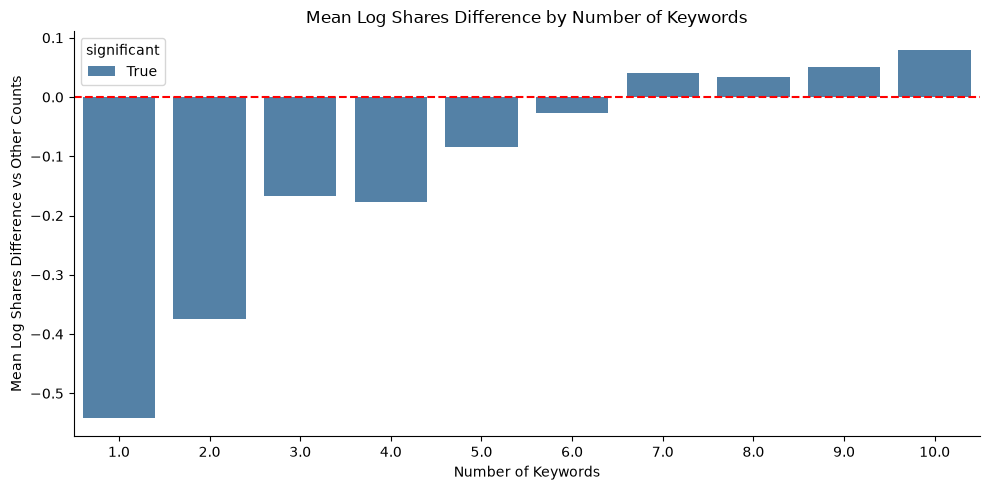

In [69]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="num_keywords",
    y="mean_difference",
    hue="significant",
    palette={True: "steelblue", False: "gray"},
    dodge=False
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Mean Log Shares Difference by Number of Keywords")
plt.xlabel("Number of Keywords")
plt.ylabel("Mean Log Shares Difference vs Other Counts")

sns.despine()
plt.tight_layout()
plt.show()

In [67]:
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

df_test = df[["num_keywords", "shares"]].dropna()

results = []

for count in sorted(df_test["num_keywords"].unique()):
    group = df_test.loc[df_test["num_keywords"] == count, "shares"]
    other = df_test.loc[df_test["num_keywords"] != count, "shares"]

    if len(group) < 30 or len(other) < 30:
        continue

    _, p_value = ttest_ind(group, other, equal_var=False)

    results.append({
        "num_keywords": count,
        "n": len(group),
        "mean_difference": group.mean() - other.mean(),
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p_adjusted"] = multipletests(
    results_df["p_value"], method="holm"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

display(results_df.sort_values("num_keywords"))

,num_keywords,n,mean_difference,p_value,p_adjusted,significant
0,1.0,49,-0.541788,2.915874e-03,1.166350e-02,True
1,2.0,38,-0.375165,1.925714e-02,3.851429e-02,True
2,3.0,568,-0.167640,3.628480e-05,2.539936e-04,True
3,4.0,2192,-0.177729,4.354642e-20,4.354642e-19,True
4,5.0,4359,-0.085037,4.444615e-09,3.555692e-08,True
5,6.0,6155,-0.027773,3.234861e-02,3.851429e-02,True
6,7.0,6572,0.041152,1.221614e-03,7.329681e-03,True
7,8.0,5453,0.034298,1.262679e-02,3.788037e-02,True
8,9.0,4277,0.050142,1.225882e-03,7.329681e-03,True
9,10.0,6017,0.079787,1.429056e-09,1.286151e-08,True


The number of metadata keywords (num_keywords) exhibits a statistically significant but very weak positive monotonic association with article popularity (Spearman's ρ = 0.0716, p = 8.88 × 10⁻⁴²). Welch's t-tests with Holm correction further indicate that articles containing 1–6 keywords have significantly lower mean log-shares than their respective comparison groups, whereas articles containing 7–10 keywords have significantly higher values. Despite the consistent pattern, the small correlation coefficient suggests limited standalone predictive value. The feature will be retained for further evaluation during model development.

## keywords of shared articles

In [74]:
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

kw_features = [
    "kw_min_min", "kw_max_min", "kw_avg_min",
    "kw_min_max", "kw_max_max", "kw_avg_max",
    "kw_min_avg", "kw_max_avg", "kw_avg_avg"
]

results = []

for feature in kw_features:
    rho, p_value = spearmanr(
        df[feature],
        df["shares"],
        nan_policy="omit"
    )

    results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p_value
    })

kw_results = pd.DataFrame(results)

kw_results["p_adjusted"] = multipletests(
    kw_results["p_value"],
    method="holm"
)[1]

kw_results["significant"] = kw_results["p_adjusted"] < 0.05

display(
    kw_results.sort_values(
        "spearman_rho", ascending=False
    ).round(5)
)

,feature,spearman_rho,p_value,p_adjusted,significant
8,kw_avg_avg,0.25467,0.00000,0.00000,True
7,kw_max_avg,0.22279,0.00000,0.00000,True
6,kw_min_avg,0.10278,0.00000,0.00000,True
2,kw_avg_min,0.09532,0.00000,0.00000,True
1,kw_max_min,0.09225,0.00000,0.00000,True
3,kw_min_max,0.05641,0.00000,0.00000,True
5,kw_avg_max,0.03520,0.00000,0.00000,True
0,kw_min_min,0.00711,0.17944,0.17944,False
4,kw_max_max,-0.03311,0.00000,0.00000,True


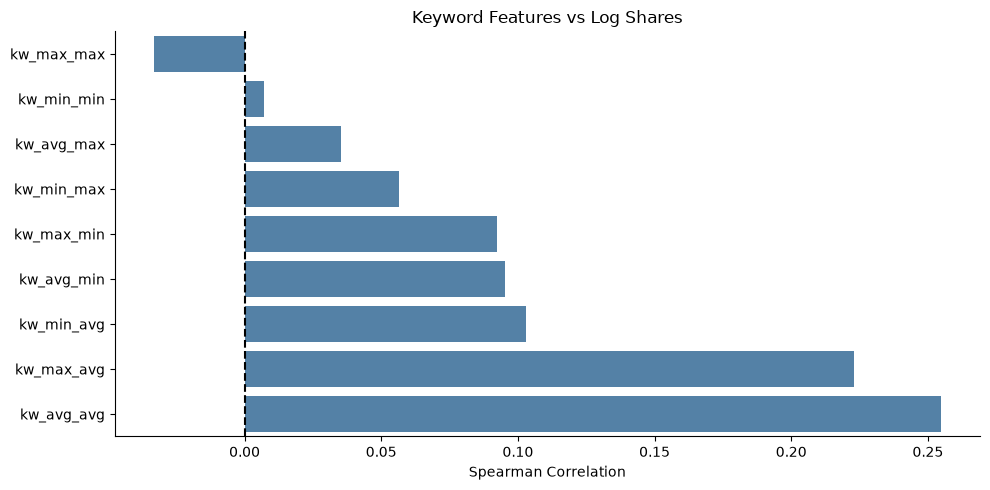

In [76]:
plot_df = kw_results.sort_values("spearman_rho")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=plot_df,
    x="spearman_rho",
    y="feature",
    color="steelblue"
)

plt.axvline(0, color="black", linestyle="--")

plt.title("Keyword Features vs Log Shares")
plt.xlabel("Spearman Correlation")
plt.ylabel("")

sns.despine()
plt.tight_layout()
plt.show()

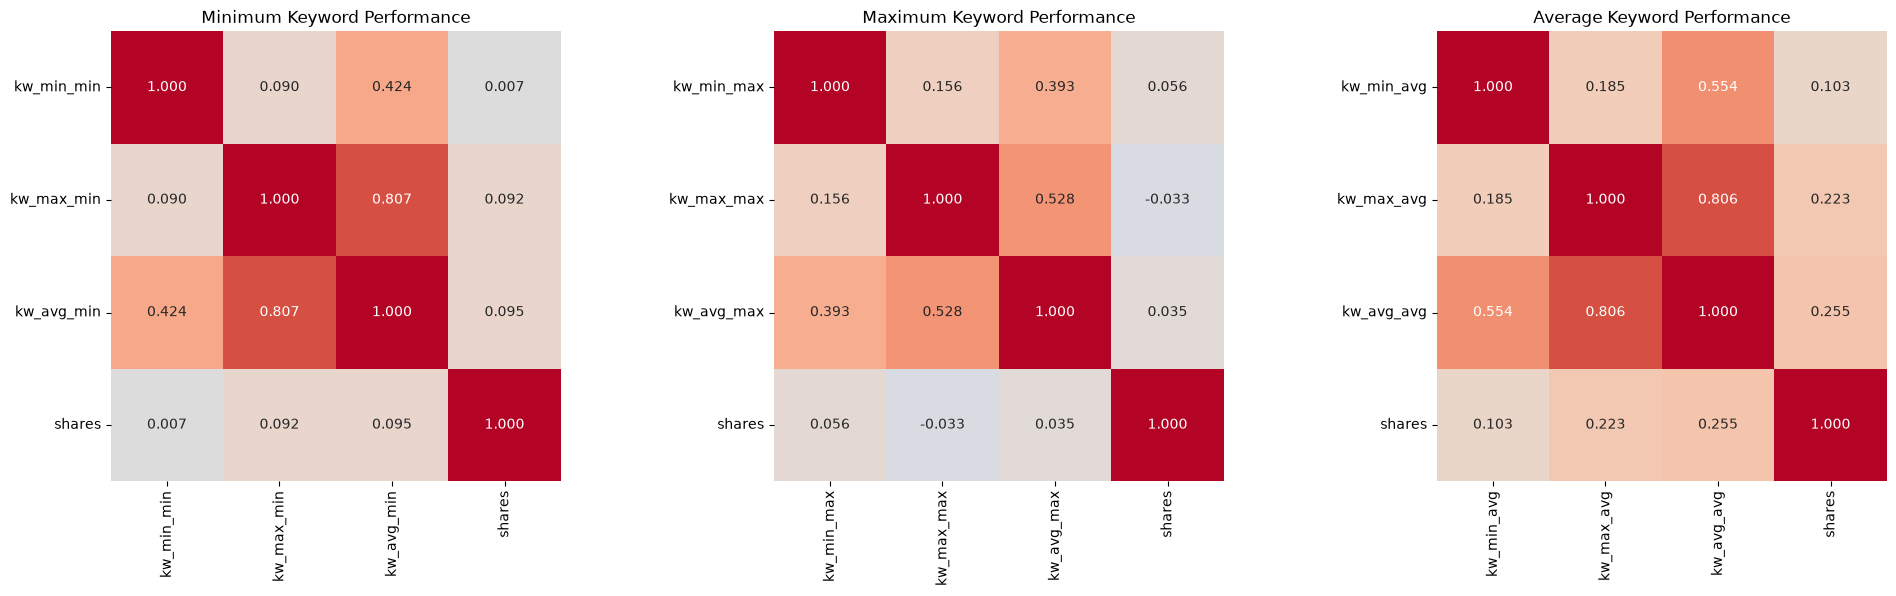

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

groups = {
    "Minimum Keyword Performance": [
        "kw_min_min", "kw_max_min", "kw_avg_min"
    ],
    "Maximum Keyword Performance": [
        "kw_min_max", "kw_max_max", "kw_avg_max"
    ],
    "Average Keyword Performance": [
        "kw_min_avg", "kw_max_avg", "kw_avg_avg"
    ]
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (title, features) in zip(axes, groups.items()):

    corr_matrix = df[features + ["shares"]].corr(
        method="spearman"
    )

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax,
        cbar=False
    )

    ax.set_title(title)
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [82]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

groups = {
    "Minimum Keyword Performance": [
        "kw_min_min", "kw_max_min", "kw_avg_min"
    ],
    "Maximum Keyword Performance": [
        "kw_min_max", "kw_max_max", "kw_avg_max"
    ],
    "Average Keyword Performance": [
        "kw_min_avg", "kw_max_avg", "kw_avg_avg"
    ]
}

vif_tables = {}

for group_name, features in groups.items():

    X = df[features].replace([np.inf, -np.inf], np.nan).dropna()
    X = add_constant(X, has_constant="add")

    vif_df = pd.DataFrame({
        "feature": features,
        "VIF": [
            variance_inflation_factor(
                X.values,
                X.columns.get_loc(feature)
            )
            for feature in features
        ]
    }).sort_values("VIF", ascending=False)

    vif_tables[group_name] = (
        vif_df["feature"] + ": " + vif_df["VIF"].map("{:.3f}".format)
    ).reset_index(drop=True)

# Display all three groups side by side
display(pd.DataFrame(vif_tables))

,Minimum Keyword Performance,Maximum Keyword Performance,Average Keyword Performance
0,kw_avg_min: 8.905,kw_avg_max: 1.842,kw_avg_avg: 5.042
1,kw_max_min: 8.792,kw_max_max: 1.538,kw_max_avg: 4.052
2,kw_min_min: 1.095,kw_min_max: 1.263,kw_min_avg: 1.736


Keyword-performance features exhibit varying degrees of association with article popularity, with kw_avg_avg (ρ = 0.255) and kw_max_avg (ρ = 0.223) showing the strongest positive relationships. Several features are strongly intercorrelated, suggesting overlapping information. While these findings indicate potential predictive value, the incremental contribution of individual features remains uncertain and should be assessed through cross-validated feature ablation.


VIF analysis identified substantial within-group multicollinearity among minimum keyword-performance features, particularly kw_avg_min (VIF = 8.905) and kw_max_min (VIF = 8.792). Moderate multicollinearity was also observed for kw_avg_avg (VIF = 5.042) and kw_max_avg (VIF = 4.052). Conversely, the maximum keyword-performance group exhibited low VIF values throughout. These findings suggest potential feature redundancy, warranting further evaluation through cross-validated feature selection rather than immediate feature removal.